### Package versions

Run the cell below to record the exact package versions used to generate the results in this notebook.


In [1]:
# --- Environment / package versions (added for reproducibility) ---
import sys
try:
    from importlib.metadata import version, PackageNotFoundError
except ImportError:
    from importlib_metadata import version, PackageNotFoundError
print("Python:", sys.version.split()[0])
for _pkg in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "seaborn", "gseapy", "pyliftover", "openpyxl", "requests", "pyBigWig", "pyreadr", "adjustText", "pypdf", "pingouin"]:
    try:
        print(f"{_pkg}: {version(_pkg)}")
    except PackageNotFoundError:
        pass


Python: 3.10.12
numpy: 2.2.6
pandas: 2.3.3
scipy: 1.15.3
statsmodels: 0.14.6
matplotlib: 3.10.9
seaborn: 0.13.2
gseapy: 1.3.1
openpyxl: 3.1.5
requests: 2.34.2
pyreadr: 0.5.6
adjustText: 1.4.0
pypdf: 6.13.1
pingouin: 0.6.1


# Fig. 1E–F — Independent validation of SLC38A4 dysregulation (ISAIAH cohort)

##### Author: Inês


----
# ISAIAH Cohort — SLC38A4 Liver Expression Analysis
## Independent validation of SLC38A4 dysregulation in severe
## alcohol-related hepatitis

### Trial background
The ISAIAH trial (**IL-1 Signal Inhibition in Alcohol-Related Hepatitis**)
was a Phase II, multicentre, randomised, double-blind, placebo-controlled
trial of **canakinumab** (a monoclonal anti-IL-1β antibody, 3 mg/kg) versus
**placebo** in patients with biopsy-confirmed severe alcohol-related
hepatitis (mDF ≥ 32, MELD ≤ 27). Fifty-seven participants were randomised
1:1; liver biopsies were obtained at **baseline (day 0)** and **day 28**
post-treatment. The primary endpoint was histological improvement in
hepatic inflammation at day 28.

> **RNA-seq data source (liver biopsy transcriptomics):**
> Rodrigo-Torres D, et al. Longitudinal paired liver biopsies and
> transcriptome profiling in alcohol-associated hepatitis reveal dynamic
> changes in cellular senescence. *Gut.* 2025;74(9):1500–1513.
> doi:10.1136/gutjnl-2024-334094. PMID: 40122595

> **Primary clinical trial publication:**
> Vergis N, et al. IL-1 Signal Inhibition in Alcohol-Related Hepatitis:
> A Randomized, Double-Blind, Placebo-Controlled Trial of Canakinumab.
> *Clin Gastroenterol Hepatol.* 2025;23(5):797–807.
> doi:10.1016/j.cgh.2024.07.025. PMID: 39181422

### Role of this dataset in the current manuscript
SLC38A4 expression data from the ISAIAH liver biopsy RNA-seq provides an
**independent clinical validation cohort** for the transcriptomic findings
from the InTEAM dataset. Specifically, this dataset is used to:
- Validate that SLC38A4 is downregulated in SAH liver biopsies from an
  independent patient cohort
- Examine whether SLC38A4 expression correlates with disease severity
  (MELD score) at baseline
- Assess whether pharmacological inhibition of IL-1β (canakinumab) —
  a key suppressor of SLC38A4 expression identified in our in vitro
  experiments — is associated with changes in hepatic SLC38A4 expression
  at day 28

### Data in this file (`ISAIAH_SLC38A4_metadata_counts.rds`)
| Column | Description |
|--------|-------------|
| `id` | Patient identifier (n = 32 with expression data) |
| `timepoint` | `d0` = baseline biopsy; `d28` = day 28 biopsy |
| `treatment` | `0` = placebo; `1` = canakinumab |
| `SLC38A4_CLR_counts` | SLC38A4 expression from liver biopsy RNA-seq, centred log-ratio (CLR) normalised — do **not** re-transform |
| `MELD` | MELD score at each timepoint |

### Key notes
- **n = 32 patients** have expression data (subset of 57 randomised)
- **31 patients** have paired biopsies at both d0 and d28
- **CLR normalisation** is a compositional normalisation appropriate for
  RNA-seq count data; values (~1.9–5.7) are already on a log-like scale
- All statistical tests use **non-parametric methods** given the small n

In [2]:
# ============================================================
# IMPORTS AND SETTINGS
# ============================================================
import pyreadr
import pandas as pd
import numpy as np
from scipy.stats import wilcoxon
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import os
import warnings
import logging
from scipy.stats import spearmanr, mannwhitneyu, wilcoxon

logging.getLogger('fontTools').setLevel(logging.ERROR)
warnings.filterwarnings('ignore', category=FutureWarning)

print(f"pandas:     {pd.__version__}")
print(f"matplotlib: {matplotlib.__version__}")
print(f"seaborn:    {sns.__version__}")

plt.rcParams.update({
    'font.family':     'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size':       10,
    'pdf.fonttype':    42,
    'ps.fonttype':     42
})

# Outputs are written flat into this folder, alongside the notebook (see repo README).

# ============================================================
# LOAD DATA
# ============================================================
result = pyreadr.read_r("ISAIAH_SLC38A4_metadata_counts.rds")
df     = result[None].copy()

# ============================================================
# STANDARDISE COLUMNS
# ============================================================
df["id"]        = df["id"].astype(str)
df["timepoint"] = df["timepoint"].astype(str).str.strip().str.lower()
df["treatment"] = df["treatment"].astype(str).str.strip()

# CORRECT treatment labels for ISAIAH trial
# treatment 0 = placebo, treatment 1 = canakinumab
treatment_labels = {"0": "Placebo", "1": "Canakinumab"}
df["treatment_label"] = df["treatment"].map(treatment_labels)

EXPR_COL   = "SLC38A4_CLR_counts"
MELD_COL   = "MELD"
EXPR_LABEL = "SLC38A4 expression\n(CLR-normalised, liver biopsy)"

print(f"✅ Data loaded: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"\nTimepoints:  {df['timepoint'].value_counts().to_dict()}")
print(f"Treatments:  {df['treatment_label'].value_counts().to_dict()}")

paired_counts = df.groupby("id")["timepoint"].count()
print(f"\nPatients with paired biopsies (d0+d28): {(paired_counts==2).sum()}")
print(f"Patients with single timepoint:          {(paired_counts==1).sum()}")

display(df.head(8))

pandas:     2.3.3
matplotlib: 3.10.9
seaborn:    0.13.2
✅ Data loaded: 59 rows × 6 columns

Timepoints:  {'d0': 30, 'd28': 29}
Treatments:  {'Placebo': 32, 'Canakinumab': 27}

Patients with paired biopsies (d0+d28): 27
Patients with single timepoint:          5


,id,timepoint,treatment,SLC38A4_CLR_counts,MELD,treatment_label
0,1019,d0,0,3.711223,22.89492,Placebo
1,1019,d28,0,4.011066,19.97656,Placebo
2,1023,d0,0,3.423620,19.89153,Placebo
3,1023,d28,0,4.124151,14.01951,Placebo
4,1029,d0,1,4.404034,19.92165,Canakinumab
5,1029,d28,1,5.689120,14.53193,Canakinumab
6,106,d0,1,4.205887,20.80047,Canakinumab
7,1077,d0,0,2.698247,22.15144,Placebo


---
## Section 1: QC — Distribution of SLC38A4 Expression and MELD

/sessions/modest-quirky-einstein/tmp/ipykernel_8/4246681458.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Baseline (d0)", "Day 28 (d28)"])
/sessions/modest-quirky-einstein/tmp/ipykernel_8/4246681458.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Baseline (d0)", "Day 28 (d28)"])


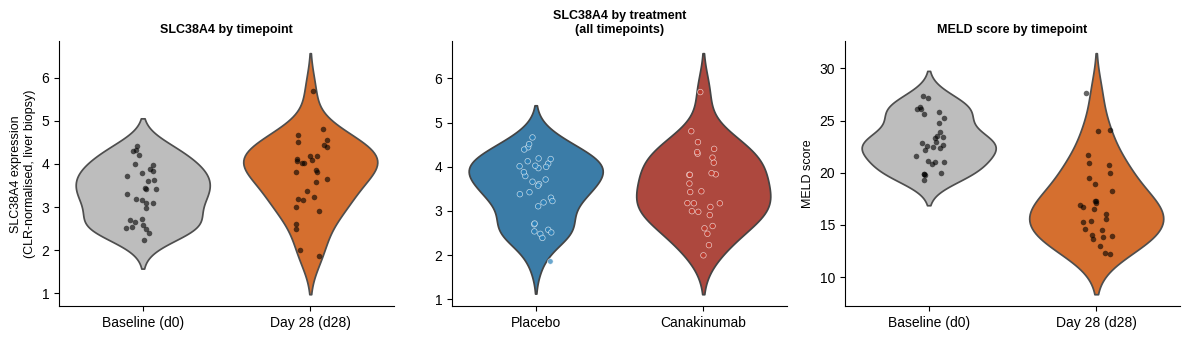

✅ QC plots saved


In [3]:
# ============================================================
# QC PLOTS
# ============================================================
palette_tp = {"d0": "#bdbdbd", "d28": "#f16913"}
palette_tx = {"Placebo": "#2980b9", "Canakinumab": "#c0392b"}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

# Panel 1: Expression by timepoint
ax = axes[0]
sns.violinplot(data=df, x="timepoint", y=EXPR_COL,
               order=["d0", "d28"], palette=palette_tp,
               inner=None, ax=ax)
sns.stripplot(data=df, x="timepoint", y=EXPR_COL,
              order=["d0", "d28"], color="black",
              size=4, alpha=0.6, jitter=True, ax=ax)
ax.set_xlabel("")
ax.set_xticklabels(["Baseline (d0)", "Day 28 (d28)"])
ax.set_ylabel(EXPR_LABEL, fontsize=9)
ax.set_title("SLC38A4 by timepoint", fontsize=9, fontweight="bold")
sns.despine(ax=ax)

# Panel 2: Expression by treatment
ax = axes[1]
sns.violinplot(data=df, x="treatment_label", y=EXPR_COL,
               order=["Placebo", "Canakinumab"], palette=palette_tx,
               inner=None, ax=ax)
sns.stripplot(data=df, x="treatment_label", y=EXPR_COL,
              order=["Placebo", "Canakinumab"],
              palette=palette_tx, size=4, alpha=0.7,
              jitter=True, edgecolor="white", linewidth=0.5, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("SLC38A4 by treatment\n(all timepoints)", fontsize=9, fontweight="bold")
sns.despine(ax=ax)

# Panel 3: MELD by timepoint
ax = axes[2]
sns.violinplot(data=df, x="timepoint", y=MELD_COL,
               order=["d0", "d28"], palette=palette_tp,
               inner=None, ax=ax)
sns.stripplot(data=df, x="timepoint", y=MELD_COL,
              order=["d0", "d28"], color="black",
              size=4, alpha=0.6, jitter=True, ax=ax)
ax.set_xlabel("")
ax.set_xticklabels(["Baseline (d0)", "Day 28 (d28)"])
ax.set_ylabel("MELD score", fontsize=9)
ax.set_title("MELD score by timepoint", fontsize=9, fontweight="bold")
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("SuppFig_ISAIAH_QC.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
print("✅ QC plots saved")

---
## Section 2: Figure 1E — Correlation of SLC38A4 Expression with MELD Score

Key question: Does lower SLC38A4 expression associate with higher MELD
(worse liver function) in SAH patients?
Analysed across all timepoints combined (n = 59), and separately by timepoint.


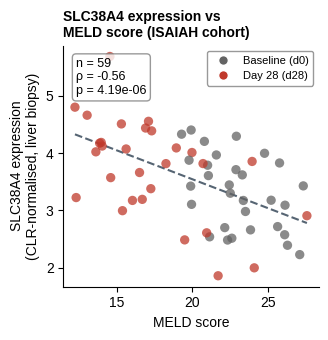

✅ Figure 1E saved
   n = 59, Spearman ρ = -0.559, p = 4.19e-06


In [4]:
# ============================================================
# FIGURE 1E — Spearman correlation: SLC38A4 vs MELD
# Main figure: combined timepoints only (n = 59)
# ============================================================

fig, ax = plt.subplots(figsize=(3.5, 3.5))

subset = df.copy()
x = subset[MELD_COL].values
y = subset[EXPR_COL].values
n = len(subset)

rho, pval = spearmanr(x, y)
p_str = f"p = {pval:.2e}" if pval < 0.001 else f"p = {pval:.3f}"

# Colour points by timepoint for visual clarity
colors_tp = subset["timepoint"].map({"d0": "#636363", "d28": "#c0392b"})

ax.scatter(x, y,
           c=colors_tp,
           alpha=0.75, s=45,
           linewidths=0, zorder=3)

# Regression line
m, b   = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 100)
ax.plot(x_line, m * x_line + b,
        color="#2c3e50", linewidth=1.5,
        linestyle="--", alpha=0.8, zorder=2)

# Legend for timepoint colours
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="#636363", markersize=7,
           label="Baseline (d0)"),
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="#c0392b", markersize=7,
           label="Day 28 (d28)")
]
ax.legend(handles=legend_elements, fontsize=8,
          loc="upper right", frameon=True,
          framealpha=0.8, edgecolor="grey")

# Annotation
ax.text(0.05, 0.95,
        f"n = {n}\nρ = {rho:.2f}\n{p_str}",
        transform=ax.transAxes, fontsize=9,
        va="top", ha="left",
        bbox=dict(boxstyle="round,pad=0.3",
                  facecolor="white",
                  edgecolor="grey",
                  alpha=0.8))

ax.set_xlabel("MELD score", fontsize=10)
ax.set_ylabel(EXPR_LABEL, fontsize=10)
ax.set_title("SLC38A4 expression vs\nMELD score (ISAIAH cohort)",
             fontsize=10, fontweight="bold", loc="left")
sns.despine(ax=ax)
plt.tight_layout()

plt.savefig("Fig1E_ISAIAH_SLC38A4_MELD_combined.pdf",
            format="pdf", bbox_inches="tight")
plt.show()

print(f"✅ Figure 1E saved")
print(f"   n = {n}, Spearman ρ = {rho:.3f}, p = {pval:.2e}")

corr_results = [{
    "Timepoint":    "Combined (d0 + d28)",
    "n":            n,
    "Spearman rho": round(rho, 3),
    "P-value":      f"{pval:.2e}"
}]


In [5]:
# ============================================================
# SENSITIVITY ANALYSIS -- repeated measures correlation (rmcorr)
# The n = 59 combined-timepoints Spearman correlation above (Fig. 1E) pools
# two non-independent observations per patient for the 27 patients with
# paired biopsies. As a sensitivity check accounting for this repeated-
# measures structure, we additionally compute the repeated measures
# correlation (rmcorr; Bakdash & Marusich, 2017) across those 27 paired
# patients. Reported in SI Methods 1.4 and SI Results Section 3.
# ============================================================
import pingouin as pg

paired_only = df[df["id"].isin(
    df.groupby("id")["timepoint"].nunique()[lambda s: s == 2].index
)].copy()

rmcorr_result = pg.rm_corr(data=paired_only, x=MELD_COL, y=EXPR_COL, subject="id")
r_rm    = rmcorr_result["r"].iloc[0]
p_rm    = rmcorr_result["pval"].iloc[0]
dof_rm  = rmcorr_result["dof"].iloc[0]

print("Repeated measures correlation (sensitivity check for Fig. 1E):")
print(f"  n patients (paired) = {paired_only['id'].nunique()}, dof = {dof_rm}")
print(f"  r = {r_rm:.3f}, p = {p_rm:.3f}")
print(f"  (cf. combined-timepoints Spearman above: rho = {rho:.3f}, p = {pval:.2e}, n = {n})")


Repeated measures correlation (sensitivity check for Fig. 1E):
  n patients (paired) = 27, dof = 26
  r = -0.542, p = 0.003
  (cf. combined-timepoints Spearman above: rho = -0.559, p = 4.19e-06, n = 59)


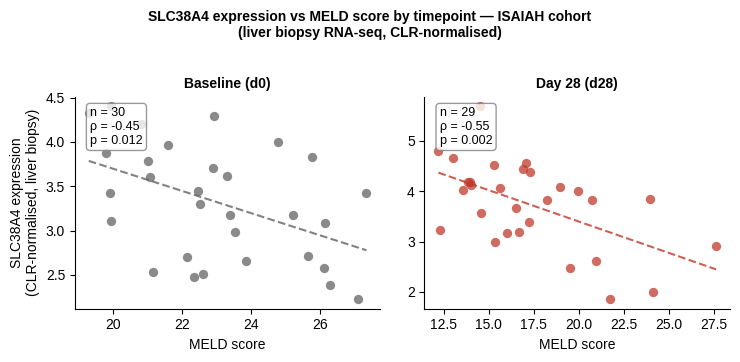


📊 Spearman correlation results by timepoint:


,Timepoint,n,Spearman rho,P-value
0,Baseline (d0),30,-0.451,1.25e-02
1,Day 28 (d28),29,-0.545,2.22e-03


✅ Fig. S3A saved


In [6]:
# ============================================================
# SUPPLEMENTARY — SLC38A4 vs MELD correlation by timepoint
# Panels: d0 (baseline) and d28 separately
# ============================================================

timepoints = ["d0", "d28"]
tp_labels  = {"d0": "Baseline (d0)", "d28": "Day 28 (d28)"}
tp_colors  = {"d0": "#636363",       "d28": "#c0392b"}

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.5))
supp_corr_results = []

for i, (tp, ax) in enumerate(zip(timepoints, axes)):

    subset = df[df["timepoint"] == tp].copy()
    x      = subset[MELD_COL].values
    y      = subset[EXPR_COL].values
    n      = len(subset)
    color  = tp_colors[tp]

    rho, pval = spearmanr(x, y)
    p_str = f"p = {pval:.2e}" if pval < 0.001 else f"p = {pval:.3f}"

    # Scatter
    ax.scatter(x, y,
               color=color, alpha=0.75, s=45,
               linewidths=0, zorder=3)

    # Regression line
    m, b   = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_line, m * x_line + b,
            color=color, linewidth=1.5,
            linestyle="--", alpha=0.8, zorder=2)

    # Annotation
    ax.text(0.05, 0.95,
            f"n = {n}\nρ = {rho:.2f}\n{p_str}",
            transform=ax.transAxes, fontsize=9,
            va="top", ha="left",
            bbox=dict(boxstyle="round,pad=0.3",
                      facecolor="white",
                      edgecolor="grey",
                      alpha=0.8))

    ax.set_xlabel("MELD score", fontsize=10)
    ax.set_ylabel(EXPR_LABEL if i == 0 else "", fontsize=10)
    ax.set_title(tp_labels[tp], fontsize=10, fontweight="bold")
    sns.despine(ax=ax)

    supp_corr_results.append({
        "Timepoint":    tp_labels[tp],
        "n":            n,
        "Spearman rho": round(rho, 3),
        "P-value":      f"{pval:.2e}"
    })

plt.suptitle(
    "SLC38A4 expression vs MELD score by timepoint — ISAIAH cohort\n"
    "(liver biopsy RNA-seq, CLR-normalised)",
    fontsize=10, fontweight="bold", y=1.02
)
plt.tight_layout()

plt.savefig(
    "Fig_S3A_ISAIAH_SLC38A4_MELD_by_timepoint.pdf",
    format="pdf", bbox_inches="tight"
)
plt.show()

print("\n📊 Spearman correlation results by timepoint:")
display(pd.DataFrame(supp_corr_results))
print("✅ Fig. S3A saved")

---
## Section 3: SLC38A4 Expression by Treatment Group

Key question: Does canakinumab (IL-1β inhibition) affect SLC38A4 expression
in liver biopsies compared to placebo?
Analysed at baseline (d0) and day 28 (d28) separately.

Scientific rationale: If SLC38A4 is suppressed by inflammatory mediators
including IL-1β (as shown in our in vitro data), canakinumab treatment
might partially restore SLC38A4 expression at day 28.

/sessions/modest-quirky-einstein/tmp/ipykernel_8/2656643983.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(groups, fontsize=10)
/sessions/modest-quirky-einstein/tmp/ipykernel_8/2656643983.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(groups, fontsize=10)


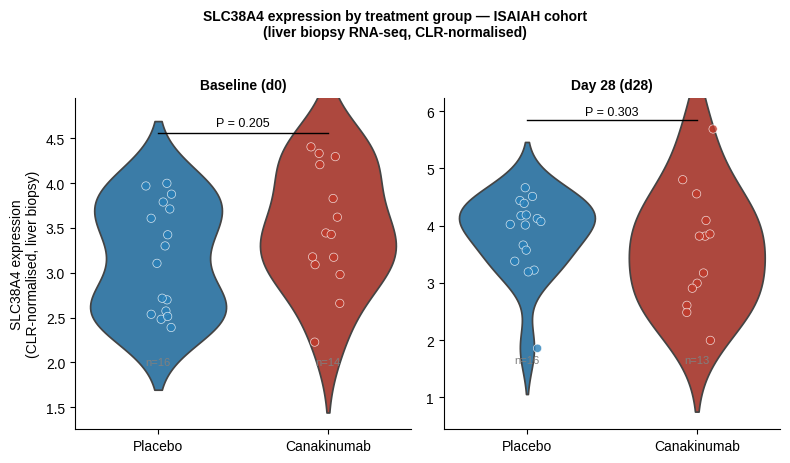


📊 Treatment comparison results:


,Timepoint,Placebo n,Placebo median,Canakinumab n,Canakinumab median,P-value (MWU)
0,Baseline (d0),16,3.202,14,3.436,2.05e-01
1,Day 28 (d28),16,4.048,13,3.817,3.03e-01


✅ Supplementary figure saved


In [7]:
# ============================================================
# SLC38A4 by treatment group at each timepoint
# ============================================================
groups    = ["Placebo", "Canakinumab"]
tp_order  = ["d0", "d28"]
tp_titles = {"d0": "Baseline (d0)", "d28": "Day 28 (d28)"}

fig, axes = plt.subplots(1, 2, figsize=(8, 4.5))
tx_results = []

for i, (tp, ax) in enumerate(zip(tp_order, axes)):

    subset = df[df["timepoint"] == tp].copy()
    g_plac = subset[subset["treatment_label"] == "Placebo"][EXPR_COL]
    g_cana = subset[subset["treatment_label"] == "Canakinumab"][EXPR_COL]

    # Mann-Whitney U test
    if len(g_plac) >= 3 and len(g_cana) >= 3:
        stat, pval = mannwhitneyu(g_plac, g_cana, alternative="two-sided")
        p_str = f"P = {pval:.2e}" if pval < 0.001 else f"P = {pval:.3f}"
    else:
        pval, p_str = np.nan, "n too small"

    sns.violinplot(data=subset, x="treatment_label", y=EXPR_COL,
                   order=groups, palette=palette_tx,
                   inner=None, ax=ax)
    sns.stripplot(data=subset, x="treatment_label", y=EXPR_COL,
                  order=groups, palette=palette_tx,
                  size=6, alpha=0.8, jitter=True,
                  edgecolor="white", linewidth=0.5, ax=ax)

    # Significance bar
    y_max = subset[EXPR_COL].max()
    y_bar = y_max + 0.15
    ax.plot([0, 1], [y_bar, y_bar], color="black", linewidth=1)
    ax.text(0.5, y_bar + 0.05, p_str,
            ha="center", va="bottom", fontsize=9)
    ax.set_ylim(None, y_bar + 0.4)

    # Add n per group
    for j, (grp, g_data) in enumerate(
        zip(groups, [g_plac, g_cana])
    ):
        ax.text(j, subset[EXPR_COL].min() - 0.25,
                f"n={len(g_data)}", ha="center", fontsize=8,
                color="grey")

    ax.set_xlabel("")
    ax.set_ylabel(EXPR_LABEL if i == 0 else "", fontsize=10)
    ax.set_title(tp_titles[tp], fontsize=10, fontweight="bold")
    ax.set_xticklabels(groups, fontsize=10)
    sns.despine(ax=ax)

    tx_results.append({
        "Timepoint":          tp_titles[tp],
        "Placebo n":          len(g_plac),
        "Placebo median":     round(g_plac.median(), 3),
        "Canakinumab n":      len(g_cana),
        "Canakinumab median": round(g_cana.median(), 3),
        "P-value (MWU)":      f"{pval:.2e}" if not np.isnan(pval) else "n/a"
    })

plt.suptitle(
    "SLC38A4 expression by treatment group — ISAIAH cohort\n"
    "(liver biopsy RNA-seq, CLR-normalised)",
    fontsize=10, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.savefig("SuppFig_ISAIAH_SLC38A4_treatment.pdf",
            format="pdf", bbox_inches="tight")
plt.show()

print("\n📊 Treatment comparison results:")
display(pd.DataFrame(tx_results))
print("✅ Supplementary figure saved")

---
## Section 4: Paired Longitudinal Analysis (d0 → d28)

For patients with both timepoints, examine:
1. Whether SLC38A4 changes from baseline to day 28
2. Whether this change differs between canakinumab and placebo
3. Whether change in SLC38A4 correlates with change in MELD

Paired patients: 27

Change in SLC38A4 (d28 - d0) by treatment:
                 count   mean    std    min    25%    50%    75%    max
treatment_label                                                        
Canakinumab       13.0  0.164  0.762 -1.136 -0.270 -0.051  0.765  1.383
Placebo           14.0  0.612  1.031 -1.932  0.116  0.751  1.326  1.865

Change in MELD (d28 - d0) by treatment:
                 count   mean    std    min    25%    50%    75%    max
treatment_label                                                        
Canakinumab       13.0 -4.697  2.996 -9.757 -6.651 -5.274 -3.016  2.373
Placebo           14.0 -6.603  2.761 -9.634 -8.266 -6.918 -5.902  0.697


/sessions/modest-quirky-einstein/tmp/ipykernel_8/2603426193.py:99: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(groups, fontsize=9)


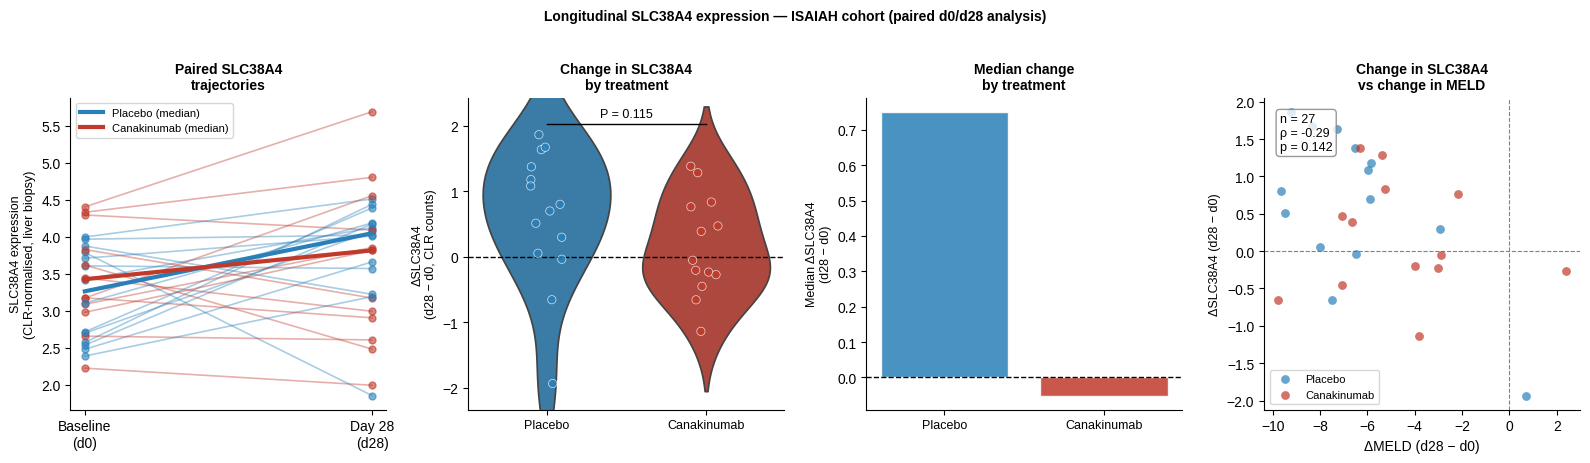


📊 Wilcoxon signed-rank (within-treatment d0 vs d28):


,Treatment,n,Median d0,Median d28,Median Δ,P (Wilcoxon)
0,Placebo,14,3.264,4.048,0.751,4.19e-02
1,Canakinumab,13,3.428,3.817,-0.051,4.97e-01


✅ Paired analysis saved


In [8]:
# ============================================================
# PAIRED ANALYSIS — d0 to d28
# Only patients with BOTH timepoints
# ============================================================

# Build wide-format paired dataframe
paired_ids = df.groupby("id")["timepoint"].count()
paired_ids = paired_ids[paired_ids == 2].index

paired_df = (
    df[df["id"].isin(paired_ids)]
    .pivot(index="id", columns="timepoint",
           values=[EXPR_COL, MELD_COL])
)
paired_df.columns = [f"{val}_{tp}" for val, tp in paired_df.columns]
paired_df = paired_df.reset_index()

# Add treatment label from d0 row
tx_map = (df[df["timepoint"] == "d0"]
          .set_index("id")["treatment_label"].to_dict())
paired_df["treatment_label"] = paired_df["id"].map(tx_map)

# Compute deltas
paired_df["delta_expr"] = (
    paired_df[f"{EXPR_COL}_d28"] - paired_df[f"{EXPR_COL}_d0"]
)
paired_df["delta_MELD"] = (
    paired_df[f"{MELD_COL}_d28"] - paired_df[f"{MELD_COL}_d0"]
)

print(f"Paired patients: {len(paired_df)}")
print(f"\nChange in SLC38A4 (d28 - d0) by treatment:")
print(paired_df.groupby("treatment_label")["delta_expr"]
      .describe().round(3))
print(f"\nChange in MELD (d28 - d0) by treatment:")
print(paired_df.groupby("treatment_label")["delta_MELD"]
      .describe().round(3))

# ============================================================
# PLOT — 4 panels
# ============================================================
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))

# --- Panel 1: Paired trajectories by treatment
ax = axes[0]
for _, row in paired_df.iterrows():
    color = palette_tx.get(row["treatment_label"], "#636363")
    ax.plot([0, 1],
            [row[f"{EXPR_COL}_d0"], row[f"{EXPR_COL}_d28"]],
            color=color, alpha=0.4, linewidth=1.2)
    ax.scatter([0, 1],
               [row[f"{EXPR_COL}_d0"], row[f"{EXPR_COL}_d28"]],
               color=color, s=25, zorder=3, alpha=0.6)

# Median lines per treatment
for tx, color in palette_tx.items():
    sub = paired_df[paired_df["treatment_label"] == tx]
    ax.plot([0, 1],
            [sub[f"{EXPR_COL}_d0"].median(),
             sub[f"{EXPR_COL}_d28"].median()],
            color=color, linewidth=3, zorder=5,
            label=f"{tx} (median)")

ax.set_xticks([0, 1])
ax.set_xticklabels(["Baseline\n(d0)", "Day 28\n(d28)"], fontsize=10)
ax.set_ylabel(EXPR_LABEL, fontsize=9)
ax.set_title("Paired SLC38A4\ntrajectories",
             fontsize=10, fontweight="bold")
ax.legend(fontsize=8, loc="upper left")
sns.despine(ax=ax)

# --- Panel 2: Delta expression by treatment
ax = axes[1]
g0_d = paired_df[paired_df["treatment_label"] == "Placebo"]["delta_expr"]
g1_d = paired_df[paired_df["treatment_label"] == "Canakinumab"]["delta_expr"]

if len(g0_d) >= 3 and len(g1_d) >= 3:
    stat_d, pval_d = mannwhitneyu(g0_d, g1_d, alternative="two-sided")
    p_str_d = f"P = {pval_d:.2e}" if pval_d < 0.001 else f"P = {pval_d:.3f}"
else:
    p_str_d = "n/a"

sns.violinplot(data=paired_df, x="treatment_label", y="delta_expr",
               order=groups, palette=palette_tx, inner=None, ax=ax)
sns.stripplot(data=paired_df, x="treatment_label", y="delta_expr",
              order=groups, palette=palette_tx,
              size=6, alpha=0.8, jitter=True,
              edgecolor="white", linewidth=0.5, ax=ax)
ax.axhline(0, linestyle="--", color="black", linewidth=1)
y_max_d = paired_df["delta_expr"].abs().max() + 0.1
ax.plot([0, 1], [y_max_d, y_max_d], color="black", linewidth=1)
ax.text(0.5, y_max_d + 0.05, p_str_d,
        ha="center", va="bottom", fontsize=9)
ax.set_ylim(-y_max_d - 0.3, y_max_d + 0.4)
ax.set_xlabel("")
ax.set_ylabel("ΔSLC38A4\n(d28 − d0, CLR counts)", fontsize=9)
ax.set_title("Change in SLC38A4\nby treatment",
             fontsize=10, fontweight="bold")
ax.set_xticklabels(groups, fontsize=9)
sns.despine(ax=ax)

# --- Panel 3: Wilcoxon within each treatment
ax = axes[2]
wilcoxon_results = []
medians_delta = []

for tx, color in palette_tx.items():
    sub = paired_df[paired_df["treatment_label"] == tx]
    if len(sub) >= 5:
        stat_w, pval_w = wilcoxon(
            sub[f"{EXPR_COL}_d0"],
            sub[f"{EXPR_COL}_d28"]
        )
        wilcoxon_results.append({
            "Treatment":      tx,
            "n":              len(sub),
            "Median d0":      round(sub[f"{EXPR_COL}_d0"].median(), 3),
            "Median d28":     round(sub[f"{EXPR_COL}_d28"].median(), 3),
            "Median Δ":       round(sub["delta_expr"].median(), 3),
            "P (Wilcoxon)":   f"{pval_w:.2e}"
        })
        medians_delta.append({
            "tx": tx, "median": sub["delta_expr"].median(),
            "color": color
        })

# Bar chart
for j, item in enumerate(medians_delta):
    ax.bar(j, item["median"], color=item["color"],
           edgecolor="white", alpha=0.85)
ax.axhline(0, linestyle="--", color="black", linewidth=1)
ax.set_xticks(range(len(medians_delta)))
ax.set_xticklabels([m["tx"] for m in medians_delta], fontsize=9)
ax.set_ylabel("Median ΔSLC38A4\n(d28 − d0)", fontsize=9)
ax.set_title("Median change\nby treatment",
             fontsize=10, fontweight="bold")
sns.despine(ax=ax)

# --- Panel 4: Delta SLC38A4 vs delta MELD
ax = axes[3]
for tx, color in palette_tx.items():
    sub = paired_df[paired_df["treatment_label"] == tx]
    ax.scatter(sub["delta_MELD"], sub["delta_expr"],
               color=color, alpha=0.7, s=40,
               label=tx, linewidths=0, zorder=3)

# Overall correlation
rho_d, pval_d2 = spearmanr(
    paired_df["delta_MELD"], paired_df["delta_expr"]
)
p_str_d2 = f"p = {pval_d2:.2e}" if pval_d2 < 0.001 else f"p = {pval_d2:.3f}"
ax.text(0.05, 0.95,
        f"n = {len(paired_df)}\nρ = {rho_d:.2f}\n{p_str_d2}",
        transform=ax.transAxes, fontsize=9,
        va="top", ha="left",
        bbox=dict(boxstyle="round,pad=0.3",
                  facecolor="white", edgecolor="grey", alpha=0.8))
ax.axhline(0, linestyle="--", color="grey", linewidth=0.8)
ax.axvline(0, linestyle="--", color="grey", linewidth=0.8)
ax.set_xlabel("ΔMELD (d28 − d0)", fontsize=10)
ax.set_ylabel("ΔSLC38A4 (d28 − d0)", fontsize=9)
ax.set_title("Change in SLC38A4\nvs change in MELD",
             fontsize=10, fontweight="bold")
ax.legend(fontsize=8)
sns.despine(ax=ax)

plt.suptitle(
    "Longitudinal SLC38A4 expression — ISAIAH cohort (paired d0/d28 analysis)",
    fontsize=10, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.savefig(
    "SuppFig_ISAIAH_SLC38A4_paired_longitudinal.pdf",
    format="pdf", bbox_inches="tight"
)
plt.show()

print("\n📊 Wilcoxon signed-rank (within-treatment d0 vs d28):")
display(pd.DataFrame(wilcoxon_results))
print("✅ Paired analysis saved")

---
## Section 5: Overall Paired Analysis — SLC38A4 Change from Baseline to Day 28

Key question: Does SLC38A4 expression change systematically from baseline to day 28
across all paired patients, regardless of treatment arm?


In [9]:
# ============================================================
# OVERALL WILCOXON — all 27 paired patients
# Simplest summary: does SLC38A4 change from d0 to d28?
# ============================================================

from scipy.stats import wilcoxon

all_d0  = paired_df[f"{EXPR_COL}_d0"].values
all_d28 = paired_df[f"{EXPR_COL}_d28"].values
all_delta = paired_df["delta_expr"].values

stat_all, pval_all = wilcoxon(all_d0, all_d28)

n_total   = len(paired_df)
n_up_all  = (all_delta > 0).sum()
n_dn_all  = (all_delta < 0).sum()
med_delta = np.median(all_delta)

p_str_all = (f"p = {pval_all:.3f}"
             if pval_all >= 0.001 else f"p = {pval_all:.2e}")

print("=" * 55)
print("OVERALL WILCOXON — ALL PAIRED PATIENTS")
print("=" * 55)
print(f"  n                  : {n_total}")
print(f"  Median d0          : {np.median(all_d0):.3f}")
print(f"  Median d28         : {np.median(all_d28):.3f}")
print(f"  Median Δ (d28−d0)  : {med_delta:+.3f}")
print(f"  Patients increased : {n_up_all}/{n_total}")
print(f"  Patients decreased : {n_dn_all}/{n_total}")
print(f"  Wilcoxon p         : {p_str_all}")

OVERALL WILCOXON — ALL PAIRED PATIENTS
  n                  : 27
  Median d0          : 3.424
  Median d28         : 3.855
  Median Δ (d28−d0)  : +0.472
  Patients increased : 17/27
  Patients decreased : 10/27
  Wilcoxon p         : p = 0.028


---
### SI cross-check — SLC38A4 change in the MELD-improved subgroup

The Supplementary Results state: *“with recovery most pronounced in the 25 patients whose MELD score
improved over this period (median change in expression = +0.51 CLR units, p=0.005)”*. This was not
previously computed in this notebook — the cell below reproduces it directly from `paired_df` (Section 4/5
above), restricting the same paired Wilcoxon signed-rank test used for the full cohort (Section 5) to the
subgroup with ΔMELD < 0 (MELD score improved from d0 to d28).


In [10]:
# ============================================================
# SUBGROUP ANALYSIS — SLC38A4 change in patients with MELD improvement
# Key question: among patients whose MELD score improved from d0 to d28,
# is the increase in SLC38A4 expression itself statistically significant?
# ============================================================

meld_improved = paired_df[paired_df["delta_MELD"] < 0]
n_improved = len(meld_improved)

stat_imp, pval_imp = wilcoxon(
    meld_improved[f"{EXPR_COL}_d0"],
    meld_improved[f"{EXPR_COL}_d28"]
)

p_str_imp = (f"p = {pval_imp:.3f}"
             if pval_imp >= 0.001 else f"p = {pval_imp:.2e}")

print("=" * 55)
print("MELD-IMPROVED SUBGROUP — SLC38A4 CHANGE (d0 → d28)")
print("=" * 55)
print(f"  n (MELD improved, ΔMELD<0) : {n_improved}")
print(f"  Median Δ SLC38A4 (CLR)     : {meld_improved['delta_expr'].median():+.3f}")
print(f"  Wilcoxon p                  : {p_str_imp}")


MELD-IMPROVED SUBGROUP — SLC38A4 CHANGE (d0 → d28)
  n (MELD improved, ΔMELD<0) : 25
  Median Δ SLC38A4 (CLR)     : +0.513
  Wilcoxon p                  : p = 0.005


---
## Section 6: Figure 1F — MELD Score Change by SLC38A4 Expression Direction

Key question: In patients whose SLC38A4 expression increases from baseline to day 28,
is MELD score improvement greater than in patients whose SLC38A4 expression decreases?
Reverse-framing approach: stratify by SLC38A4 direction, examine ΔMELD.


In [11]:
# ============================================================
# SLC38A4-direction classification and stats (feeds Fig. 1F above
# and the statistics export below; no separate figure here --
# the plotted version of this analysis is Fig. 1F. An earlier
# draft also produced a redundant "Fig1G" 3-panel figure
# duplicating Fig. 1F (removed 2026-08-14: not cited anywhere,
# and Panel A was an exact duplicate of Fig. 1F).
# ============================================================

from scipy.stats import mannwhitneyu, wilcoxon
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np
import pandas as pd

# ============================================================
# STEP 1: CLASSIFY BY SLC38A4 DIRECTION
# ============================================================

paired_df["SLC38A4_direction"] = paired_df["delta_expr"].apply(
    lambda x: "Increased" if x > 0 else "Decreased"
)

groups    = ["Increased", "Decreased"]
palette   = {"Increased": "#27ae60", "Decreased": "#c0392b"}

print("=" * 55)
print("CLASSIFICATION BY SLC38A4 DIRECTION")
print("=" * 55)
print(paired_df["SLC38A4_direction"].value_counts().to_string())

# ============================================================
# STEP 2: STATISTICS
# Primary: does ΔMELD differ between SLC38A4 groups?
# Secondary: within each group, does MELD change significantly?
# Also: what proportion of SLC38A4-increasers improve MELD?
# ============================================================

print("\n" + "=" * 55)
print("ΔMELD BY SLC38A4 DIRECTION")
print("=" * 55)

group_stats = []
for group in groups:
    sub      = paired_df[paired_df["SLC38A4_direction"] == group]
    n_g      = len(sub)
    delta_m  = sub["delta_MELD"].values
    n_meld_improved = (delta_m < 0).sum()

    print(f"\n  SLC38A4 {group} (n={n_g}):")
    print(f"    Median ΔMELD          : {np.median(delta_m):+.3f}")
    print(f"    IQR                   : "
          f"[{np.percentile(delta_m, 25):+.2f}, "
          f"{np.percentile(delta_m, 75):+.2f}]")
    print(f"    MELD improved (Δ < 0) : "
          f"{n_meld_improved}/{n_g} "
          f"({100*n_meld_improved/n_g:.0f}%)")

    group_stats.append({
        "SLC38A4 direction": group,
        "n": n_g,
        "Median ΔMELD": round(np.median(delta_m), 3),
        "IQR ΔMELD": (f"[{np.percentile(delta_m,25):.2f}, "
                      f"{np.percentile(delta_m,75):.2f}]"),
        "MELD improved n (%)": (f"{n_meld_improved} "
                                f"({100*n_meld_improved/n_g:.0f}%)")
    })

# Between-group comparison: ΔMELD
inc  = paired_df[
    paired_df["SLC38A4_direction"] == "Increased"]["delta_MELD"]
dec  = paired_df[
    paired_df["SLC38A4_direction"] == "Decreased"]["delta_MELD"]

stat_mw, pval_mw = mannwhitneyu(inc, dec, alternative="two-sided")
p_str_mw = (f"p = {pval_mw:.3f}"
            if pval_mw >= 0.001 else f"p = {pval_mw:.2e}")

print(f"\n  Between-group ΔMELD (Mann-Whitney U): {p_str_mw}")

# Proportion of MELD improvers in SLC38A4 increasers
from scipy.stats import binomtest
n_inc       = len(inc)
n_meld_imp_in_inc = (inc < 0).sum()
binom_res   = binomtest(
    n_meld_imp_in_inc, n_inc, p=0.5, alternative="greater"
)
binom_p_str = (f"p = {binom_res.pvalue:.3f}"
               if binom_res.pvalue >= 0.001
               else f"p = {binom_res.pvalue:.2e}")

print(f"\n  Among SLC38A4 increasers (n={n_inc}):")
print(f"    MELD improved: {n_meld_imp_in_inc}/{n_inc}")
print(f"    Binomial test (H0: p=0.5): {binom_p_str}")


CLASSIFICATION BY SLC38A4 DIRECTION
SLC38A4_direction
Increased    17
Decreased    10

ΔMELD BY SLC38A4 DIRECTION

  SLC38A4 Increased (n=17):
    Median ΔMELD          : -6.542
    IQR                   : [-7.99, -5.84]
    MELD improved (Δ < 0) : 17/17 (100%)

  SLC38A4 Decreased (n=10):
    Median ΔMELD          : -3.903
    IQR                   : [-6.93, -2.94]
    MELD improved (Δ < 0) : 8/10 (80%)

  Between-group ΔMELD (Mann-Whitney U): p = 0.139

  Among SLC38A4 increasers (n=17):
    MELD improved: 17/17
    Binomial test (H0: p=0.5): p = 7.63e-06


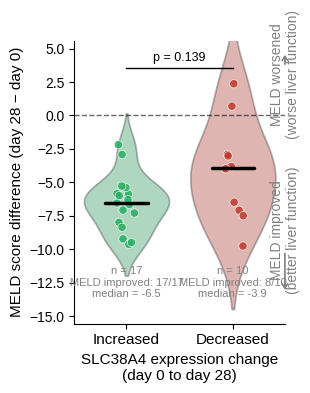

✅ Figure 1F saved


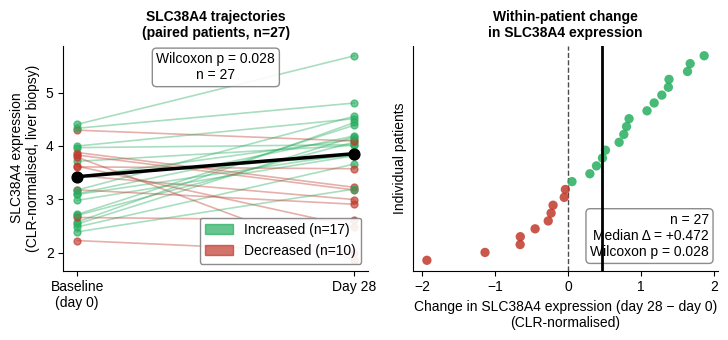

✅ Fig. S3B,C saved


In [12]:
# ============================================================
# FIGURE 1F — MELD score change by SLC38A4 expression direction
# ΔMELD by SLC38A4 direction
# Shows both magnitude difference and concordance proportions
# ============================================================

fig, ax = plt.subplots(figsize=(3.2, 4))

palette_dir = {
    "Increased": "#27ae60",
    "Decreased": "#c0392b"
}
order = ["Increased", "Decreased"]

# --- Violin + strip
sns.violinplot(
    data=paired_df,
    x="SLC38A4_direction", y="delta_MELD",
    order=order,
    palette=palette_dir,
    inner=None, ax=ax,
    alpha=0.4
)
sns.stripplot(
    data=paired_df,
    x="SLC38A4_direction", y="delta_MELD",
    order=order,
    palette=palette_dir,
    size=6, alpha=0.85, jitter=True,
    edgecolor="white", linewidth=0.5, ax=ax
)

# --- Reference line at zero
ax.axhline(
    0, linestyle="--", color="black",
    linewidth=1, alpha=0.6
)

# --- Median markers
for j, group in enumerate(order):
    sub = paired_df[
        paired_df["SLC38A4_direction"] == group
    ]
    med = sub["delta_MELD"].median()
    ax.plot(
        [j - 0.2, j + 0.2],
        [med, med],
        color="black", linewidth=2.5,
        zorder=5, solid_capstyle="round"
    )

# --- Significance bar
y_bar = paired_df["delta_MELD"].max() + 1.2
ax.plot(
    [0, 1], [y_bar, y_bar],
    color="black", linewidth=1
)
ax.text(
    0.5, y_bar + 0.3,
    "p = 0.139",
    ha="center", va="bottom", fontsize=9
)
ax.set_ylim(None, y_bar + 2)

# --- Concordance and n annotations below x-axis
annotations = [
    (0, 17, 17, -6.5),
    (1, 10,  8, -3.9)
]
for x_pos, n_g, n_imp, med in annotations:
    ax.text(
        x_pos,
        paired_df["delta_MELD"].min() - 1.5,
        f"n = {n_g}\n"
        f"MELD improved: {n_imp}/{n_g}\n"
        f"median = {med:+.1f}",
        ha="center", va="top",
        fontsize=8, color="grey"
    )

# --- X-axis labels
ax.set_xticks([0, 1])
ax.set_xticklabels(
    ["Increased", "Decreased"],
    fontsize=11
)
ax.set_xlabel(
    "SLC38A4 expression change\n(day 0 to day 28)",
    fontsize=11
)
ax.set_ylabel(
    "MELD score difference (day 28 − day 0)",
    fontsize=11
)

sns.despine(ax=ax)

# Get current y-axis limits
y_min, y_max = ax.get_ylim()
y_range = y_max - y_min

# Left x position — just outside the left spine
x_label = 1  # adjust left/right if needed

# Upper label — MELD worsened
ax.annotate(
    "MELD worsened\n(worse liver function)",
    xy=(x_label, y_max * 0.55),
    xycoords=("axes fraction", "data"),
    fontsize=10,
    color="grey",
    ha="center",
    va="center",
    rotation=90,
    annotation_clip=False
)

# Arrow pointing up (worse)
ax.annotate(
    "",
    xy=(x_label, y_max * 0.85),
    xytext=(x_label, y_max * 0.65),
    xycoords=("axes fraction", "data"),
    textcoords=("axes fraction", "data"),
    arrowprops=dict(
        arrowstyle="->,head_width=0.2,head_length=0.3",
        color="grey",
        lw=1.2
    ),
    annotation_clip=False
)

# Lower label — MELD improved
ax.annotate(
    "MELD improved\n(better liver function)",
    xy=(x_label, y_min * 0.55),
    xycoords=("axes fraction", "data"),
    fontsize=10,
    color="grey",
    ha="center",
    va="center",
    rotation=90,
    annotation_clip=False
)

# Arrow pointing down (better)
ax.annotate(
    "",
    xy=(x_label, y_min * 0.85),
    xytext=(x_label, y_min * 0.65),
    xycoords=("axes fraction", "data"),
    textcoords=("axes fraction", "data"),
    arrowprops=dict(
        arrowstyle="->,head_width=0.2,head_length=0.3",
        color="grey",
        lw=1.2
    ),
    annotation_clip=False
)

plt.tight_layout()

plt.savefig(
    "Fig1F_MELD_by_SLC38A4_direction.pdf",
    format="pdf", bbox_inches="tight"
)
plt.show()
print("✅ Figure 1F saved")


# ============================================================
# SUPPLEMENTARY FIGURE 2
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.5))

# -------------------------------------------------------
# Panel D: Spaghetti — SLC38A4 trajectories
# -------------------------------------------------------
ax = axes[0]

for _, row in paired_df.iterrows():
    color = ("#27ae60" if row["delta_expr"] > 0
             else "#c0392b")
    ax.plot(
        [0, 1],
        [row[f"{EXPR_COL}_d0"],
         row[f"{EXPR_COL}_d28"]],
        color=color, alpha=0.4, linewidth=1.2
    )
    ax.scatter(
        [0, 1],
        [row[f"{EXPR_COL}_d0"],
         row[f"{EXPR_COL}_d28"]],
        color=color, s=25, zorder=3, alpha=0.65
    )

# Overall median
ax.plot(
    [0, 1],
    [paired_df[f"{EXPR_COL}_d0"].median(),
     paired_df[f"{EXPR_COL}_d28"].median()],
    color="black", linewidth=2.5, zorder=5
)
ax.scatter(
    [0, 1],
    [paired_df[f"{EXPR_COL}_d0"].median(),
     paired_df[f"{EXPR_COL}_d28"].median()],
    color="black", s=60, zorder=6
)

ax.text(
    0.5, 0.97,
    f"Wilcoxon p = 0.028\nn = 27",
    transform=ax.transAxes,
    fontsize=10, ha="center", va="top",
    bbox=dict(boxstyle="round,pad=0.3",
              facecolor="white",
              edgecolor="grey", alpha=0.9)
)

up_patch = mpatches.Patch(
    color="#27ae60", alpha=0.7,
    label="Increased (n=17)"
)
dn_patch = mpatches.Patch(
    color="#c0392b", alpha=0.7,
    label="Decreased (n=10)"
)
ax.legend(
    handles=[up_patch, dn_patch],
    fontsize=10, loc="lower right",
    frameon=True, framealpha=0.9,
    edgecolor="grey"
)
ax.set_xticks([0, 1])
ax.set_xticklabels(
    ["Baseline\n(day 0)", "Day 28"],
    fontsize=10
)
ax.set_ylabel(EXPR_LABEL, fontsize=10)
ax.set_title(
    f"SLC38A4 trajectories\n(paired patients, n=27)",
    fontsize=10, fontweight="bold"
)
sns.despine(ax=ax)

# -------------------------------------------------------
# Panel E: Dot plot of individual Δ values
# -------------------------------------------------------
ax = axes[1]

all_delta    = paired_df["delta_expr"].values
sorted_idx   = np.argsort(all_delta)
sorted_delta = all_delta[sorted_idx]
sorted_colors = [
    "#27ae60" if d > 0 else "#c0392b"
    for d in sorted_delta
]

ax.scatter(
    sorted_delta,
    np.arange(len(sorted_delta)),
    c=sorted_colors, s=45,
    alpha=0.85, linewidths=0, zorder=3
)
ax.axvline(
    0, color="black", linewidth=1,
    linestyle="--", alpha=0.7
)
ax.axvline(
    np.median(all_delta),
    color="black", linewidth=2,
    linestyle="-", zorder=4
)
ax.text(
    0.97, 0.05,
    f"n = {len(paired_df)}\n"
    f"Median Δ = {np.median(all_delta):+.3f}\n"
    f"Wilcoxon p = 0.028",
    transform=ax.transAxes,
    fontsize=10, va="bottom", ha="right",
    bbox=dict(boxstyle="round,pad=0.3",
              facecolor="white",
              edgecolor="grey", alpha=0.9)
)
ax.set_xlabel(
    "Change in SLC38A4 expression (day 28 − day 0)\n(CLR-normalised)",
    fontsize=10
)
ax.set_ylabel("Individual patients", fontsize=10)
ax.set_yticks([])
ax.set_title(
    "Within-patient change\nin SLC38A4 expression",
    fontsize=10, fontweight="bold"
)
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig(
    "Fig_S3BC_ISAIAH_paired_detail.pdf",
    format="pdf", bbox_inches="tight"
)

plt.show()
print("✅ Fig. S3B,C saved")

In [13]:
# ============================================================
# EXPORT ALL STATISTICAL RESULTS
# ============================================================
output_path = "ISAIAH_SLC38A4_statistics.xlsx"

# Collect direction-stratified results table
results_df = pd.DataFrame(group_stats)
results_df["Between-group ΔMELD (Mann-Whitney)"] = [p_str_mw, ""]

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
    df.to_excel(writer, sheet_name="Raw_data", index=False)
    pd.DataFrame(corr_results).to_excel(
        writer, sheet_name="MELD_correlations", index=False)
    pd.DataFrame(tx_results).to_excel(
        writer, sheet_name="Treatment_comparisons", index=False)
    paired_df.to_excel(
        writer, sheet_name="Paired_data", index=False)
    results_df.to_excel(
        writer, sheet_name="SLC38A4_direction_stratified", index=False)

print(f"\u2705 All statistics exported to: {output_path}")


✅ All statistics exported to: ISAIAH_SLC38A4_statistics.xlsx
